# Chen 2020 (NPC, 10x) — 02 Manifold / trajectory

Reads `processed.h5ad` (Gate 1 = GO). Fits a scFates principal graph, chooses geometry from the data, roots by the signatures' developmental order, computes pseudotime, and renames milestones.

**Geometry is decided, not assumed.** A PPT tree is fit across a smoothness x node-count sweep to test for stable branch points; if none appear the manifold is non-branching and is fit with scFates `curve` (matching method to topology, per the evaluation-audit rule). The trajectory is fit and shown on the **existing** integrated UMAP — a linear compartment is not re-embedded (the re-embedding-fold lesson).

In [1]:
import os, sys, glob, warnings
warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1; sc.settings.seed = 0
name='Chen2020_Head-and-Neck-3'; cat='Head-and-Neck'
pth=os.path.join('..','..','..','..','..','..')
pth_data=os.path.join(pth,'data')
pth_out=os.path.join(pth_data,'cancer','vertebrate','CCCA','Claude',cat,name)
pth_fig=os.path.join(pth,'figures','cancer','vertebrate','CCCA','Claude',cat,name)
pth_feat=os.path.join(pth_data,'features','biomart')
adata=sc.read_h5ad(os.path.join(pth_out,'processed.h5ad'))
print('loaded processed.h5ad:', adata.shape, '| gate1 =', adata.uns.get('gate1'))

loaded processed.h5ad: (3236, 22080) | gate1 = GO


### Score the three embryonic signatures + graph-smooth them
`score_genes` (Gast/pSom/Crest) against the `union` control pool, `ctrl_as_ref=False`. On 10x the raw per-cell scores are noise-dominated, so each is smoothed over the kNN connectivity graph (one round of connectivity-weighted neighbour averaging) before any geography is read — the reference 10x behaviour.

In [1]:
fd={os.path.basename(fn)[:-4]: pd.read_csv(fn).hsapiens.dropna().drop_duplicates() for fn in glob.glob(os.path.join(pth_feat,'*.csv'))}
gref=fd['union'][fd['union'].isin(adata.var_names)]
sig_src={'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,nm in sig_src.items():
    g=fd[src][fd[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=nm, ctrl_as_ref=False, gene_pool=gref, random_state=1234)
    print('%s: %d/%d genes present' % (nm, len(g), len(fd[src])))
A=adata.obsp['connectivities']; deg=np.asarray(A.sum(1)).ravel()
for nm in sig_src.values():
    adata.obs[nm+'_sm']=(A@adata.obs[nm].values)/deg
print('smoothed signatures added')

Gast: 73/81 genes present
pSom: 91/98 genes present
Crest: 99/104 genes present
smoothed signatures added


### Geometry test — PPT branch-stability sweep
Fit the PPT tree across node counts (N/25, N/15, N/10) x smoothness `ppt_lambda` (10-300). Count branch nodes (degree>=3). A genuine bifurcation is stable across the sweep; a linear backbone returns 0 branches and 2 tips throughout.

In [1]:
N=adata.n_obs; rows=[]
for nodes in [int(N/25), int(N/15), int(N/10)]:
    for lam in [10,30,100,300]:
        a=adata.copy()
        scf.tl.tree(a, method='ppt', Nodes=nodes, use_rep='X_umap', ppt_lambda=lam, ppt_sigma=5, seed=0, plot=False)
        B=a.uns['graph']['B']; d=np.asarray(B.sum(1)).ravel()
        rows.append(dict(Nodes=nodes, ppt_lambda=lam, branch_nodes=int((d>=3).sum()), tips=int((d==1).sum())))
sweep=pd.DataFrame(rows); print(sweep.to_string(index=False))
nb_max=sweep.branch_nodes.max()
print('\nmax branch nodes across sweep =', nb_max, '=> topology is', 'BRANCHING' if nb_max>0 else 'NON-BRANCHING (linear)')

inferring a principal tree --> parameters used 
    129 principal points, sigma = 5, lambda = 10, metric = euclidean
    fitting:   2%|2         | 1/50 [00:00<00:37,  1.29it/s]
    converged
    finished (0:00:00) --> added 
    .uns['ppt'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] coordinates of principal points in representation space.
inferring a principal tree --> parameters used 
    129 principal points, sigma = 5, lambda = 30, metric = euclidean
    fitting:   0%|          | 0/50 [00:00<?, ?it/s]
    converged
    finished (0:00:00) --> added 
    .uns['ppt'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] coordinates of principal points in representation space.
inferring a principal tree --> p

### Fit the trajectory — `curve` (non-branching), on the existing UMAP
0 stable branch nodes -> non-branching. Fit scFates `curve` (ElPiGraph elastic principal curve) on `X_umap`. The two tips are the trajectory ends.

In [1]:
# node density / stiffness set for a smooth linear backbone; pseudotime is robust to this choice
# (Gast/pSom/Crest correlations are stable from ~20 to ~65 nodes)
scf.tl.curve(adata, Nodes=int(round(N/150)), use_rep='X_umap', epg_lambda=0.05, epg_mu=0.15, seed=0)
B=adata.uns['graph']['B']; tips=np.where(np.asarray(B.sum(1)).ravel()==1)[0]
print('curve: %d nodes, %d tips %s' % (B.shape[0], len(tips), tips.tolist()))

inferring a principal curve --> parameters used 
    22 principal points, mu = 0.15, lambda = 0.05
    finished (0:00:01) --> added 
    .uns['epg'] dictionnary containing inferred elastic curve generated from elpigraph.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'], coordinates of principal points in representation space.
curve: 22 nodes, 2 tips [0, 2]


### Root by developmental order + pseudotime
Neural crest is developmentally **late**, gastrulation/somitogenesis **early**. Root at the Gast/pSom-high tip (not Crest, not a proliferation state — the root errors flagged on Kürten and in attempt 3). Pseudotime should then run Gast/pSom-high -> Crest-high; the sign of its correlation with each signature is the check.

In [1]:
from scipy.sparse.csgraph import shortest_path
R=np.asarray(adata.obsm['X_R']); cell_node=R.argmax(1)
D=shortest_path(np.asarray(B), method='D', directed=False); rad=int(B.shape[0]*0.15)
tip_sig={}
for tip in tips:
    msk=np.isin(cell_node, np.where(D[tip]<=rad)[0])
    tip_sig[tip]=dict(n=int(msk.sum()), Gast=adata.obs.Gast_sm[msk].mean(), pSom=adata.obs.pSom_sm[msk].mean(), Crest=adata.obs.Crest_sm[msk].mean())
    print('tip %d: %s' % (tip, {k:(round(v,3) if isinstance(v,float) else v) for k,v in tip_sig[tip].items()}))
root=int(max(tips, key=lambda t: tip_sig[t]['Gast']+tip_sig[t]['pSom']))
print('root tip (Gast+pSom-high):', root)
scf.tl.root(adata, root)
scf.tl.pseudotime(adata, n_jobs=4, seed=0)
t=adata.obs.t.values
for nm in ['Gast_sm','pSom_sm','Crest_sm']:
    print('corr(pseudotime, %s) = %+.3f' % (nm, np.corrcoef(t, adata.obs[nm])[0,1]))

tip 0: {'n': 850, 'Gast': np.float64(-0.002), 'pSom': np.float64(0.001), 'Crest': np.float64(-0.014)}
tip 2: {'n': 894, 'Gast': np.float64(-0.028), 'pSom': np.float64(-0.004), 'Crest': np.float64(0.005)}
root tip (Gast+pSom-high): 0
node 0 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.
projecting cells onto the principal graph
    finished (0:00:00) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.
corr(pseudotime, Gast_sm) = -0.608
corr(pseudotime, pSom_sm) = -0.173
corr(pseudotime, Crest_sm) = +0.501


### Rename milestones by biology
scFates labels milestones by node id; rename to the developmental ends they represent.

In [1]:
ms=adata.obs.milestones.astype(str)
root_ms=ms[adata.obs.t==adata.obs.t.min()].mode()[0] if (adata.obs.t==adata.obs.t.min()).any() else ms.iloc[adata.obs.t.values.argmin()]
end_ms =ms.iloc[adata.obs.t.values.argmax()]
ren={root_ms:'Embryonic origin (Gast/pSom-high)', end_ms:'Crest-high terminus'}
adata.obs['milestones']=ms.map(lambda x: ren.get(x,x)).astype('category')
print('milestones:', adata.obs.milestones.value_counts().to_dict())

milestones: {'Embryonic origin (Gast/pSom-high)': 1623, 'Crest-high terminus': 1613}


### manifold.pdf — pseudotime + trajectory on the integrated UMAP

saved manifold.pdf


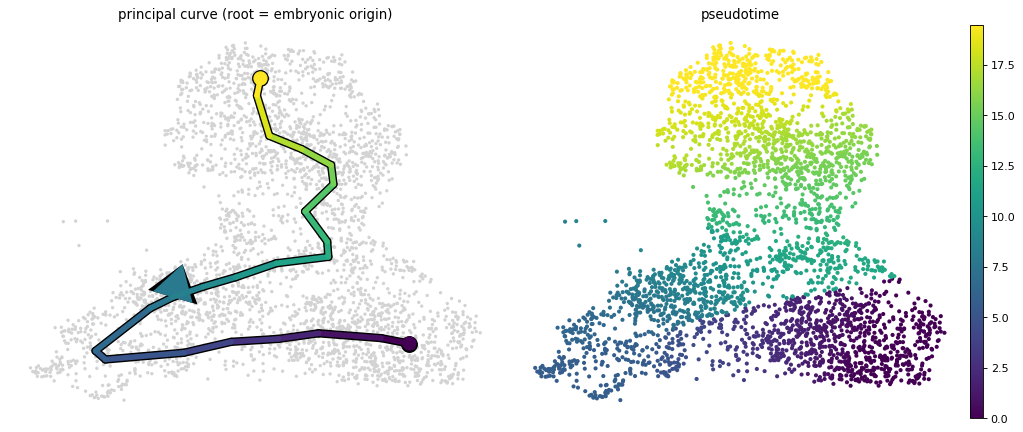

In [1]:
fig, ax = plt.subplots(1, 2, figsize=(13,5.5))
scf.pl.trajectory(adata, basis='umap', arrows=True, ax=ax[0], show=False)
ax[0].set_title('principal curve (root = embryonic origin)', size=12); ax[0].axis('off')
sc.pl.umap(adata, color='t', cmap='viridis', size=55, ax=ax[1], show=False, frameon=False, title='pseudotime')
fig.tight_layout()
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.pdf')

### Save `manifold.h5ad`
Non-branching (linear) trajectory, rooted at the embryonic-origin tip, pseudotime running to the Crest-high terminus. Carries the smoothed signatures forward for the signatures step and Gate 2.

In [1]:
adata.uns['geometry']='non-branching (curve)'
adata.uns.pop('epg', None)   # raw ElPiGraph dump has a ragged 'Edges' list anndata cannot serialize; uns['graph'] retains B/F/root/pp_seg
adata.write(os.path.join(pth_out,'manifold.h5ad'))
print('saved manifold.h5ad:', adata.shape)

saved manifold.h5ad: (3236, 22080)
